# Properties of Rectangular Waveguide

## Introduction

This example demonstrates how to use [scikit-rf](http://www.scikit-rf.org) to calculate some properties of rectangular waveguide. For more information regarding the theoretical basis for these calculations, see the [References](#References).

## Object Creation

This first section imports necessary modules and creates several `RectangularWaveguide` objects for some standard waveguide bands. 

In [1]:
%matplotlib inline
# imports
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c, mil

import skrf as rf
from skrf.frequency import Frequency
from skrf.mathFunctions import np_2_db
from skrf.media import Freespace, RectangularWaveguide

rf.stylely()
# plot formatting
plt.rcParams['lines.linewidth'] = 2

In [2]:
# create frequency objects for standard bands
f_wr5p1  = Frequency(140,220,1001, 'GHz')
f_wr3p4  = Frequency(220,330,1001, 'GHz')
f_wr2p2 = Frequency(330,500,1001, 'GHz')
f_wr1p5 = Frequency(500,750,1001, 'GHz')
f_wr1   = Frequency(750,1100,1001, 'GHz')

# create rectangular waveguide objects
wr5p1 = RectangularWaveguide(f_wr5p1.copy(), a=51*mil, b=25.5*mil, rho = 'au')
wr3p4 = RectangularWaveguide(f_wr3p4.copy(), a=34*mil, b=17*mil, rho = 'au')
wr2p2 = RectangularWaveguide(f_wr2p2.copy(), a=22*mil, b=11*mil, rho = 'au')
wr1p5 = RectangularWaveguide(f_wr1p5.copy(), a=15*mil, b=7.5*mil, rho = 'au')
wr1   = RectangularWaveguide(f_wr1.copy(), a=10*mil, b=5*mil, rho = 'au')

# add names to waveguide objects for use in plot legends
wr5p1.name = 'WR-5.1'
wr3p4.name = 'WR-3.4'
wr2p2.name = 'WR-2.2'
wr1p5.name = 'WR-1.5'
wr1.name = 'WR-1.0'

# create a list to iterate through
wg_list = [wr5p1, wr3p4,wr2p2,wr1p5,wr1]

# creat a freespace object too
freespace = Freespace(Frequency(125,1100, 1001, 'GHz'))
freespace.name = 'Free Space'

## Conductor Loss

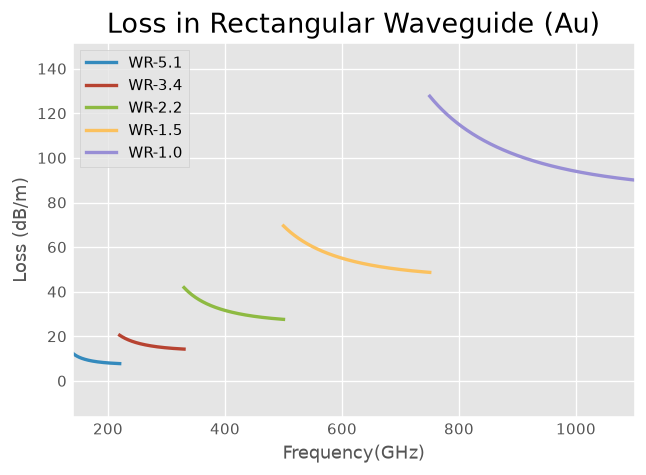

In [3]:
fig, ax = plt.subplots()

for wg in wg_list:
    wg.frequency.plot(np_2_db(wg.alpha), label=wg.name)

ax.legend()
ax.set_xlabel('Frequency(GHz)')
ax.set_ylabel('Loss (dB/m)')
ax.set_title('Loss in Rectangular Waveguide (Au)');

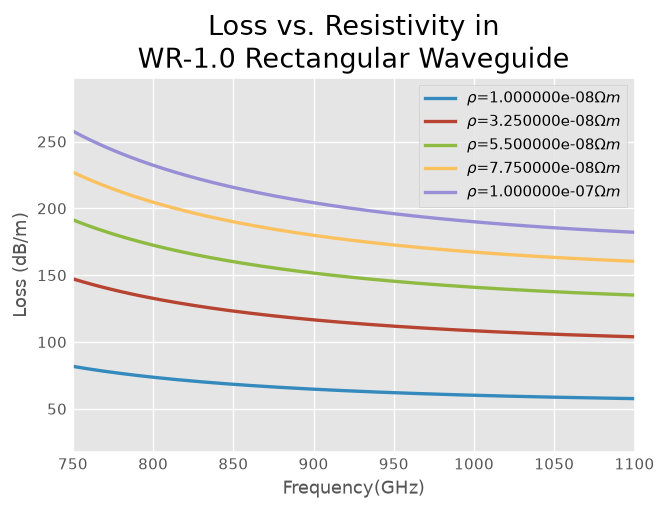

In [4]:
fig, ax = plt.subplots()
resistivity_list = np.linspace(1,10,5)*1e-8 # ohm meter
for rho in resistivity_list:
    wg = RectangularWaveguide(f_wr1.copy(), a=10*mil, b=5*mil,
                              rho = rho)
    wg.frequency.plot(np_2_db(wg.alpha),label=rf'$ \rho $={rho:e}$ \Omega m$')

ax.legend()
ax.set_xlabel('Frequency(GHz)')
ax.set_ylabel('Loss (dB/m)')
ax.set_title('Loss vs. Resistivity in\nWR-1.0 Rectangular Waveguide');

## Phase and Group Velocity

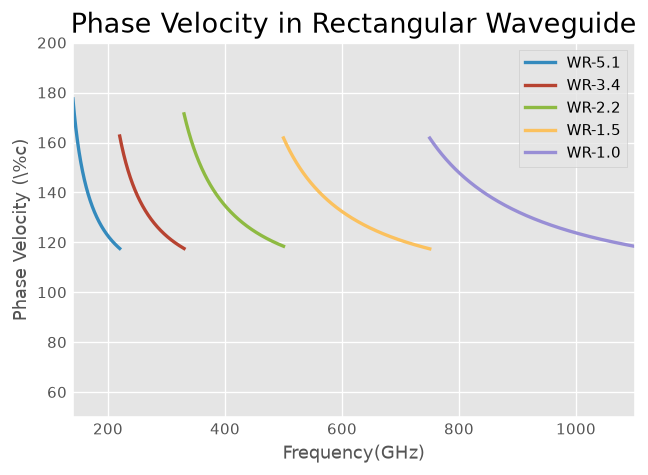

In [5]:
fig, ax = plt.subplots()
for wg in wg_list:
    wg.frequency.plot(100*wg.v_p.real/c, label=wg.name )

ax.legend()
ax.set_ylim(50,200)
ax.set_xlabel('Frequency(GHz)')
ax.set_ylabel(r'Phase Velocity (\%c)')
ax.set_title('Phase Velocity in Rectangular Waveguide');

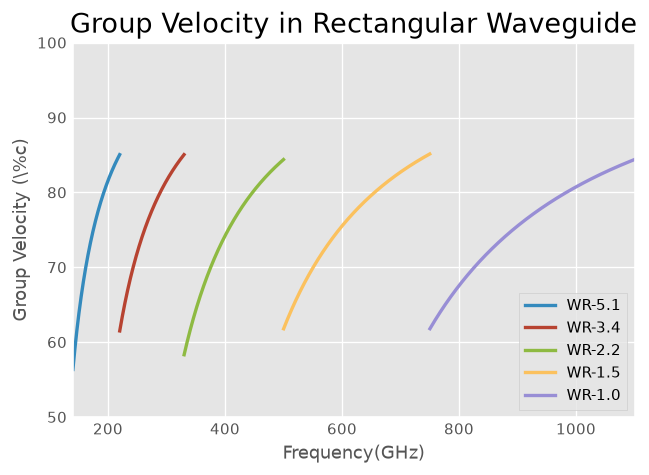

In [6]:
fig, ax = plt.subplots()
for wg in wg_list:
    plt.plot(wg.frequency.f_scaled[1:],
             100/c*np.diff(wg.frequency.w)/np.diff(wg.beta),
             label=wg.name )

ax.legend()
ax.set_ylim(50,100)
ax.set_xlabel('Frequency(GHz)')
ax.set_ylabel(r'Group Velocity (\%c)')
ax.set_title('Group Velocity in Rectangular Waveguide');

## Propagation Constant

[]

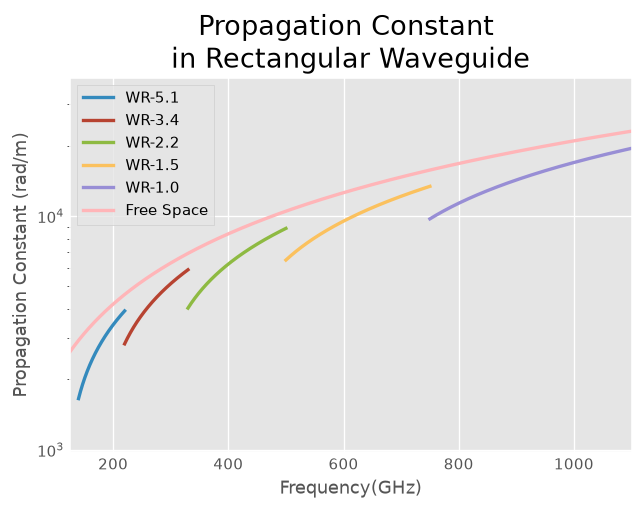

In [7]:
fig, ax = plt.subplots()
for wg in wg_list+[freespace]:
    wg.frequency.plot(wg.beta,   label=wg.name)

ax.legend()
ax.set_xlabel('Frequency(GHz)')
ax.set_ylabel('Propagation Constant (rad/m)')
ax.set_title('Propagation Constant \nin Rectangular Waveguide')
ax.semilogy()

## References


* [1] https://www.microwaves101.com/encyclopedias/waveguide-mathematics
* [2] http://en.wikipedia.org/wiki/Waveguide_(electromagnetism)
* [3] R. F. Harrington, Time-Harmonic Electromagnetic Fields (IEEE Press Series on Electromagnetic Wave Theory). Wiley-IEEE Press, 2001.
* [4] http://www.ece.rutgers.edu/~orfanidi/ewa (see Chapter 9)
